## Import setups

In [1]:
from pathlib import Path
from sklearn.base import BaseEstimator, TransformerMixin
import numpy as np 
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import make_scorer, recall_score, confusion_matrix, classification_report, precision_score
from sklearn.pipeline import Pipeline, FeatureUnion, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
import spacy 
import re 
from spacy.tokenizer import Tokenizer
from spacy.lang.en import English
import matplotlib.pyplot as plt 
import seaborn as sns
import requests

In [2]:
file_path = Path('./data/federalist_papers.txt')

Original source for the papers was an ebook in Project Gutenberg. Simply uncomment and run the cell below if the data is somehow not accessible. 

In [3]:
# r = requests.get('https://www.gutenberg.org/cache/epub/1404/pg1404.txt')
# with open(file_path , 'wb') as f:
#     f.write(r.content)

In [4]:
nlp = spacy.load('en_core_web_md')
nlp.add_pipe('sentencizer')

## Text parsing of the book 

In [5]:
f = open(file_path, 'r', encoding='utf-8')

collection_paper = []
federalist_paper = []

for f_line in f:
    if f_line.startswith('*** END OF THE PROJECT GUTENBERG'):
        break
    if f_line.startswith('FEDERALIST No.'):
        federalist_paper = [] 
        collection_paper.append(federalist_paper)
    federalist_paper.append(f_line)


print(collection_paper[0])
print(len(collection_paper))
f.close()

['FEDERALIST No. 1\n', '\n', 'General Introduction\n', '\n', 'For the Independent Journal. Saturday, October 27, 1787\n', '\n', '\n', 'HAMILTON\n', '\n', 'To the People of the State of New York:\n', '\n', 'AFTER an unequivocal experience of the inefficacy of the subsisting\n', 'federal government, you are called upon to deliberate on a new\n', 'Constitution for the United States of America. The subject speaks its\n', 'own importance; comprehending in its consequences nothing less than the\n', 'existence of the UNION, the safety and welfare of the parts of which it\n', 'is composed, the fate of an empire in many respects the most interesting\n', 'in the world. It has been frequently remarked that it seems to have been\n', 'reserved to the people of this country, by their conduct and example,\n', 'to decide the important question, whether societies of men are really\n', 'capable or not of establishing good government from reflection and\n', 'choice, or whether they are forever destined t

In [6]:

collection_paper = [[line.strip() for line in paper if line.strip()] for paper in collection_paper]

author_list = ('HAMILTON', 'JAY', 'MADISON')
collection_dict = []

for paper in collection_paper:
    paper_dict = {'paper_no': 0, 'supposed_author': '', 'content': [], 'reference': []} 

    state = 'CONTENT'
    for line in paper:
        if line.startswith('FEDERALIST No'):
            paper_dict['paper_no'] = int(re.search(r'\d+', line).group())
            continue
        if line.startswith(author_list):
            paper_dict['supposed_author'] = line
            continue
        if line == 'PUBLIUS':
            state = 'REFERENCE'
            continue
        if line.startswith('To the People of the State'):
            paper_dict['content'] = []
            continue
        if state == 'CONTENT':
            cleaned = re.sub(r'\(\d+\)', '', line)
            paper_dict['content'].append(cleaned)
        else:
            paper_dict['reference'].append(line)
    paper_dict['content'] = ' '.join(paper_dict['content'])
    collection_dict.append(paper_dict)

print(collection_dict[0])

{'paper_no': 1, 'supposed_author': 'HAMILTON', 'content': 'AFTER an unequivocal experience of the inefficacy of the subsisting federal government, you are called upon to deliberate on a new Constitution for the United States of America. The subject speaks its own importance; comprehending in its consequences nothing less than the existence of the UNION, the safety and welfare of the parts of which it is composed, the fate of an empire in many respects the most interesting in the world. It has been frequently remarked that it seems to have been reserved to the people of this country, by their conduct and example, to decide the important question, whether societies of men are really capable or not of establishing good government from reflection and choice, or whether they are forever destined to depend for their political constitutions on accident and force. If there be any truth in the remark, the crisis at which we are arrived may with propriety be regarded as the era in which that dec

In [7]:
for paper in collection_dict:
    print(paper['paper_no'], paper['supposed_author'])

1 HAMILTON
2 JAY
3 JAY
4 JAY
5 JAY
6 HAMILTON
7 HAMILTON
8 HAMILTON
9 HAMILTON
10 MADISON
11 HAMILTON
12 HAMILTON
13 HAMILTON
14 MADISON
15 HAMILTON
16 HAMILTON
17 HAMILTON
18 MADISON, with HAMILTON
19 MADISON, with HAMILTON
20 MADISON, with HAMILTON
21 HAMILTON
22 HAMILTON
23 HAMILTON
24 HAMILTON
25 HAMILTON
26 HAMILTON
27 HAMILTON
28 HAMILTON
29 HAMILTON
30 HAMILTON
31 HAMILTON
32 HAMILTON
33 HAMILTON
34 HAMILTON
35 HAMILTON
36 HAMILTON
37 MADISON
38 MADISON
39 MADISON
40 MADISON
41 MADISON
42 MADISON
43 MADISON
44 MADISON
45 MADISON
46 MADISON
47 MADISON
48 MADISON
49 MADISON
50 MADISON
51 MADISON
52 MADISON
53 MADISON
54 MADISON
55 MADISON
56 MADISON
57 MADISON
58 MADISON
59 HAMILTON
60 HAMILTON
61 HAMILTON
62 MADISON
63 MADISON
64 JAY
65 HAMILTON
66 HAMILTON
67 HAMILTON
68 HAMILTON
69 HAMILTON
70 HAMILTON
71 HAMILTON
72 HAMILTON
73 HAMILTON
74 HAMILTON
75 HAMILTON
76 HAMILTON
77 HAMILTON
78 HAMILTON
79 HAMILTON
80 HAMILTON
81 HAMILTON
82 HAMILTON
83 HAMILTON
84 HAMILTON
85 HAMILTO

Essays are separated into 4 different classes: 
1. The essays to be used for training/testing(Accepted essays)
2. Essays to be used for prediction(Disputed essays)
3. Jay's essays 
4. Essays that are jointly created by Madison and Hamilton(Joint essays).

Jay's papers aren't included with the exploratory training/testing essays(Accepted essays)due to the history of the Federalist Papers wherein he fell very sick and was only able to contribute to 5 papers(Nos. 2-5 and 64). 



In [8]:
accepted_essays = []
disputed_essays = []
joint_essays = []
jay_essays = []
disputed_no = [49,50,51,52,53,54,55,56,57,58, 62,63]
author_list = ['MADISON', 'HAMILTON']

for paper in collection_dict: 
    if paper['paper_no'] in disputed_no:
        disputed_essays.append((paper['paper_no'], paper['content'], paper['supposed_author']))
    else:
        if paper['supposed_author'] in author_list:
            accepted_essays.append((paper['paper_no'], paper['content'], paper['supposed_author']))
        elif paper['supposed_author'] == 'JAY':
            jay_essays.append((paper['paper_no'], paper['content'], paper['supposed_author']))
        else:
            joint_essays.append((paper['paper_no'], paper['content'], paper['supposed_author']))

print(f'Accepted Essays: {len(accepted_essays)}')
print(f'Disputed Essays: {len(disputed_essays)}')
print(f'Jay Essays: {len(jay_essays)}')
print(f'Joint Essays: {len(joint_essays)}')



Accepted Essays: 65
Disputed Essays: 12
Jay Essays: 5
Joint Essays: 3


In [9]:
from sklearn.model_selection import train_test_split
import pandas as pd 

accepted_essays_df = pd.DataFrame(accepted_essays)
accepted_essays_df.columns=['paper_no', 'paper', 'supposed_author']

In [10]:
accepted_essays_df.head()

,paper_no,paper,supposed_author
0,1,AFTER an unequivocal experience of the ineffic...,HAMILTON
1,6,THE three last numbers of this paper have been...,HAMILTON
2,7,"IT IS sometimes asked, with an air of seeming ...",HAMILTON
3,8,ASSUMING it therefore as an established truth ...,HAMILTON
4,9,A FIRM Union will be of the utmost moment to t...,HAMILTON


Length of text based on spacy's tokenizer to separate words. 

In [11]:

t = English()
word_tokenizer = t.tokenizer

def count_tokens(text):
    return len(word_tokenizer(text))

accepted_essays_df['length'] = accepted_essays_df['paper'].apply(count_tokens)
accepted_essays_df.head()


,paper_no,paper,supposed_author,length
0,1,AFTER an unequivocal experience of the ineffic...,HAMILTON,1754
1,6,THE three last numbers of this paper have been...,HAMILTON,2391
2,7,"IT IS sometimes asked, with an air of seeming ...",HAMILTON,2516
3,8,ASSUMING it therefore as an established truth ...,HAMILTON,2241
4,9,A FIRM Union will be of the utmost moment to t...,HAMILTON,2206


In [12]:
print(f'number of duplicated papers = {accepted_essays_df['paper'].duplicated().sum()}')
accepted_essays_df.info()


number of duplicated papers = 0
<class 'pandas.DataFrame'>
RangeIndex: 65 entries, 0 to 64
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   paper_no         65 non-null     int64
 1   paper            65 non-null     str  
 2   supposed_author  65 non-null     str  
 3   length           65 non-null     int64
dtypes: int64(2), str(2)
memory usage: 2.2 KB


Initial Paper Distribution Check

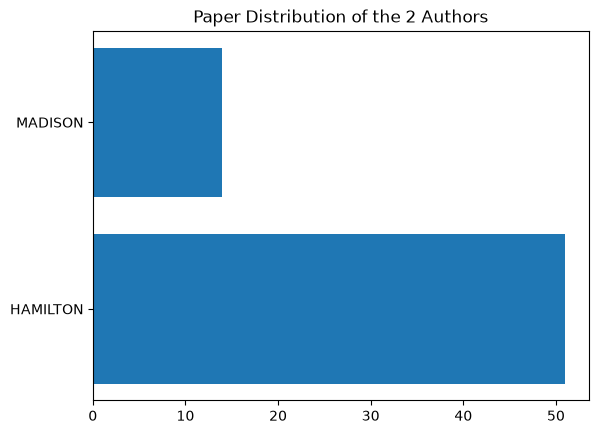

In [13]:

fig, ax = plt.subplots()
class_counts = accepted_essays_df['supposed_author'].value_counts()
ax.barh(class_counts.index.astype(str), class_counts.values)
ax.set_title('Paper Distribution of the 2 Authors')
plt.show()

Data was split into train, test for proper EDA, but the final model was switched to CV on all 65 so the test data is unused

In [14]:
train_data, test_data = train_test_split(accepted_essays_df, test_size=0.2, random_state=42, stratify=accepted_essays_df['supposed_author'])

In [15]:
train_ids = train_data['paper_no'].to_list()
test_ids = test_data['paper_no'].to_list()
assert set(train_ids).isdisjoint(test_ids)

In [16]:
train_copy = train_data.copy()
train_copy.info()
train_copy['supposed_author'].value_counts()

<class 'pandas.DataFrame'>
Index: 52 entries, 21 to 45
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   paper_no         52 non-null     int64
 1   paper            52 non-null     str  
 2   supposed_author  52 non-null     str  
 3   length           52 non-null     int64
dtypes: int64(2), str(2)
memory usage: 2.0 KB


supposed_author
HAMILTON    41
MADISON     11
Name: count, dtype: int64

Feature Engineering with Exploration on the data split

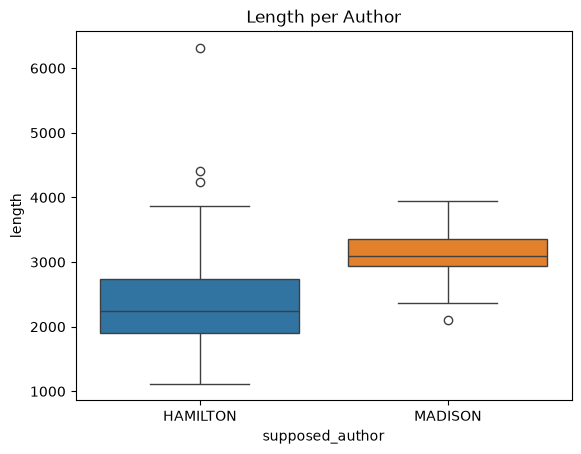

In [17]:
fig, ax = plt.subplots()
sns.boxplot(data=train_copy, x='supposed_author', y='length', ax=ax, hue='supposed_author')
ax.set_title('Length per Author')
plt.show()

In [18]:
train_doc = pd.Series(list(nlp.pipe(train_copy['paper'])), index=train_copy.index)

In [19]:
n_tokens = train_doc.apply(len)

In [20]:
def punctuation_rate(doc):
    punct_count = sum(word.is_punct for word in doc)
    return punct_count

punct_rate = (train_doc.apply(punctuation_rate)/n_tokens)*1000
punct_rate.name = 'punct_rate_1000'
punct_rate.describe()

count     52.000000
mean      99.608683
std        7.275095
min       84.905660
25%       94.505849
50%       99.641417
75%      104.262952
max      115.521136
Name: punct_rate_1000, dtype: float64

In [21]:
def unique_words(doc):
    unique_count = len(set((word.text.lower() for word in doc if not word.is_space and not word.is_punct)))
    return unique_count

unique_rate = (train_doc.apply(unique_words)/n_tokens)*1000
unique_rate.name = 'unique_rate_1000'
unique_rate.describe()

count     52.000000
mean     288.482728
std       39.693364
min      190.755105
25%      260.547563
50%      297.729657
75%      312.297713
max      380.357143
Name: unique_rate_1000, dtype: float64

In [22]:
def stop_words(doc):
    stop_count = sum(word.is_stop for word in doc)
    return stop_count 

stop_rate = (train_doc.apply(stop_words)/n_tokens)*1000
stop_rate.name = 'stop_rate_1000'
stop_rate.describe()

count     52.000000
mean     542.576578
std       14.591569
min      512.717537
25%      529.882375
50%      542.886133
75%      552.204671
max      571.023877
Name: stop_rate_1000, dtype: float64

In [23]:
assert punct_rate.index.equals(train_copy.index)
assert unique_rate.index.equals(train_copy.index)
assert stop_rate.index.equals(train_copy.index)

In [24]:
scalar_block = pd.concat([train_copy, unique_rate, punct_rate, stop_rate], axis=1)
scalar_block.head()

,paper_no,paper,supposed_author,length,unique_rate_1000,punct_rate_1000,stop_rate_1000
21,29,"THE power of regulating the militia, and of co...",HAMILTON,2460,308.130081,89.430894,547.154472
39,47,HAVING reviewed the general form of the propos...,MADISON,3099,207.486286,115.521136,516.618264
53,74,"THE President of the United States is to be ""c...",HAMILTON,1120,380.357143,107.142857,529.464286
33,41,THE Constitution proposed by the convention ma...,MADISON,3948,263.677812,99.037487,529.635258
35,43,THE FOURTH class comprises the following misce...,MADISON,3888,250.514403,114.711934,526.491770


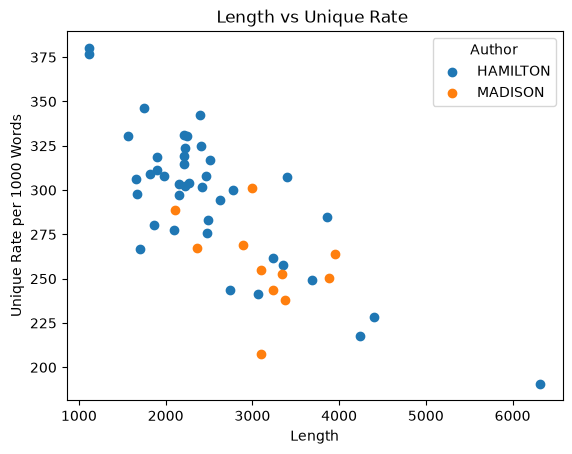

In [25]:
fig, ax = plt.subplots()
for author, group in scalar_block.groupby('supposed_author'):
    ax.scatter(group['length'], group['unique_rate_1000'],  label=author)
ax.set_title('Length vs Unique Rate ')
ax.set_xlabel('Length')
ax.set_ylabel('Unique Rate per 1000 Words')
ax.legend(title='Author')
plt.show()

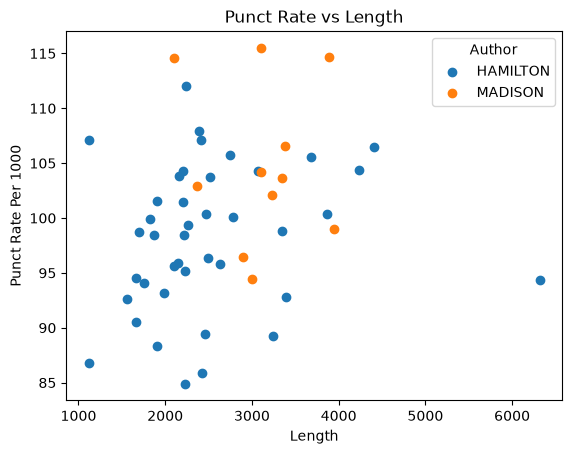

In [26]:
fig, ax = plt.subplots()
for author, group in scalar_block.groupby('supposed_author'):
    ax.scatter(group['length'], group['punct_rate_1000'], label=author)
ax.set_title('Punct Rate vs Length')
ax.set_xlabel('Length')
ax.set_ylabel('Punct Rate Per 1000')
ax.legend(title='Author')
plt.show()

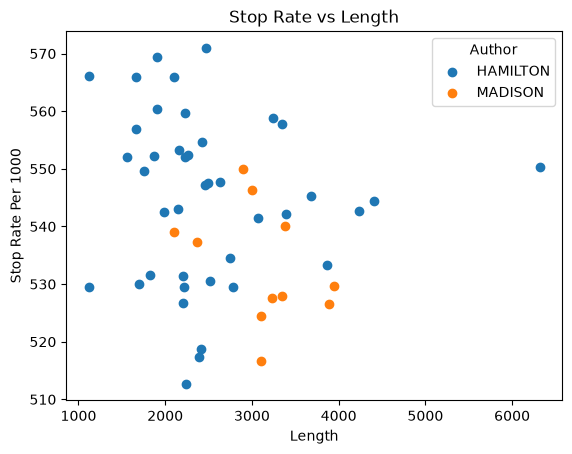

In [27]:
fig, ax = plt.subplots()
for author, group in scalar_block.groupby('supposed_author'):
    ax.scatter(group['length'], group['stop_rate_1000'], label=author)
ax.set_title('Stop Rate vs Length')
ax.set_xlabel('Length')
ax.set_ylabel('Stop Rate Per 1000')
ax.legend(title='Author')
plt.show()

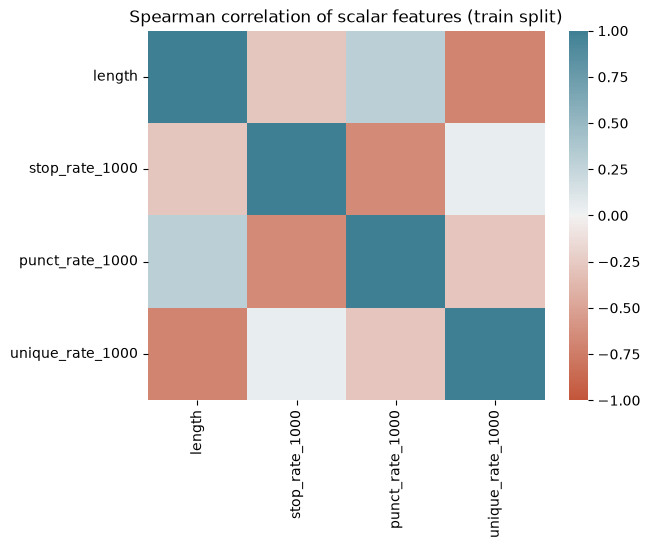

In [ ]:
Path('figures').mkdir(exist_ok=True)
fig, ax = plt.subplots()
scalar_corr = scalar_block[['length', 'stop_rate_1000', 'punct_rate_1000', 'unique_rate_1000']].corr(method='spearman', numeric_only=True)
sns.heatmap(scalar_corr, vmin=-1, vmax=1, cmap=sns.diverging_palette(20, 220, as_cmap=True))
ax.set_title('Spearman correlation of scalar features (train split)')
fig.savefig('figures/scalar_corr_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

Feature Engineering by the use of a custom sklearn transformer class

Vector Features 

In [29]:


def suffix_spacy(doc):
    return [token.suffix_ for token in doc if not token.is_punct and not token.is_stop]

def chunk_spacy(doc): 
    return [chunk.text.lower() for chunk in doc.noun_chunks if len(chunk)==2]

def pos_spacy(doc):
    return [token.pos_ for token in doc]

def common_spacy(doc):
    return [token.text.lower() for token in doc if not token.is_punct and not token.is_stop]

def stop_spacy(doc):
    return [token.text.lower() for token in doc if token.is_stop]

class BagOfRates(TransformerMixin, BaseEstimator):
    def __init__(self, analyzer, prefix, max_features=100, vocabulary=None): 
        self.analyzer = analyzer 
        self.prefix = prefix 
        self.max_features = max_features
        self.vocabulary = vocabulary
        
    def fit(self, X, y=None):
        self.cv_ = TfidfVectorizer(analyzer=self.analyzer, token_pattern=None,lowercase=False, max_features=self.max_features, vocabulary=self.vocabulary, min_df=0.5, norm='l2')
        self.cv_.fit(X)
        return self 

    def transform(self, X):
        counts = self.cv_.transform(X).toarray()
        lengths = np.array([len(doc) for doc in X]).reshape(-1,1)
        return counts

    def get_feature_names_out(self, input_features=None):
        feature_names = [f'{self.prefix}{feature}' for feature in self.cv_.get_feature_names_out()]
        return np.array(feature_names)



Scalar Features

In [30]:
def stopword_count(doc):
    return sum(token.is_stop for token in doc)

def punctuation_count(doc):
    return sum(token.is_punct for token in doc)

def unique_word_count(doc):
    words = [token.lower_ for token in doc if token.is_alpha]
    return len(set(words))

class DocRates(TransformerMixin, BaseEstimator):
    def __init__(self, analyzer):
        self.analyzer = analyzer

    def fit(self, X, y=None):
        return self 
    def transform(self, X):
        return np.array([[self.analyzer(doc)/len(doc)*1000] for doc in X])

    def get_feature_names_out(self, input_features=None):
        feature_names = [f'{self.analyzer.__name__}']
        return np.array(feature_names)

In [31]:
accepted_essays_df_copy = accepted_essays_df.copy()
accepted_essays_df_copy.set_index('paper_no', inplace=True)
docs_all, y_all = pd.Series(list(nlp.pipe(accepted_essays_df_copy['paper'])), index=accepted_essays_df_copy.index), pd.Series(accepted_essays_df_copy['supposed_author'], index=accepted_essays_df_copy.index) 

In [32]:
steps = {'stop': DocRates(stopword_count), 'punct': DocRates(punctuation_count),
         'unique': DocRates(unique_word_count),
         'common_spacy': BagOfRates(common_spacy, 'com_'), 'stop_spacy': BagOfRates(stop_spacy, 'stop_'),
         'pos_spacy': BagOfRates(pos_spacy, 'pos_'), 'suffix_spacy': BagOfRates(suffix_spacy, 'suf_'),
         'chunk_spacy': BagOfRates(chunk_spacy, 'ch_')}
sets = {'function words': ['stop_spacy'],
        'style': ['stop', 'punct', 'unique', 'stop_spacy', 'pos_spacy'],
        'topic': ['common_spacy', 'chunk_spacy'],
        'all': list(steps)}

## Model and setup comparisons

In [33]:
def make_model(keys, clf):
    union=FeatureUnion([(k, steps[k]) for k in keys]).set_output(transform='pandas')
    return Pipeline([('union', union),
                  ('scaler', StandardScaler()),
                  ('clf', clf)])

rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
scoring = {'f1': 'f1_macro',
           'madison_recall': make_scorer(recall_score, pos_label='MADISON'), 
           'madison_precision': make_scorer(precision_score, pos_label='MADISON', zero_division=0)}

def evaluate(models, X, y):
    rows = []
    for name, model in models.items():
        s = cross_validate(model, X,y,cv=rskf, scoring=scoring)
        rows.append({'model': name,
                     'f1_mean': s['test_f1'].mean(),
                     'f1_std': s['test_f1'].std(),
                     'madison_recall': s['test_madison_recall'].mean(),
                     'madison_precision': s['test_madison_precision'].mean()})
    return pd.DataFrame(rows).round(3)



In [34]:
feature_models = {name: make_model(keys, LogisticRegression(random_state=42))
                  for name, keys in sets.items()}
evaluate(feature_models, docs_all, y_all)   

,model,f1_mean,f1_std,madison_recall,madison_precision
0,function words,0.947,0.078,0.863,1.000
1,style,0.950,0.077,0.870,1.000
2,topic,0.738,0.157,0.540,0.688
3,all,0.926,0.105,0.817,0.980


In [35]:
best = sets['function words']
extra_models = {
    'LR':          make_model(best, LogisticRegression(random_state=42)),
    'LR balanced': make_model(best, LogisticRegression(class_weight='balanced', random_state=42)),
    'Tree':        make_model(best, DecisionTreeClassifier(random_state=42)),
}
evaluate(extra_models, docs_all, y_all)

,model,f1_mean,f1_std,madison_recall,madison_precision
0,LR,0.947,0.078,0.863,1.00
1,LR balanced,0.958,0.068,0.890,1.00
2,Tree,0.892,0.091,0.853,0.86


In [36]:
rng = np.random.default_rng(0)
y_shuffled = pd.Series(rng.permutation(y_all.values), index=y_all.index)
evaluate({'shuffled labels': make_model(best, LogisticRegression(random_state=42))},
         docs_all, y_shuffled)

,model,f1_mean,f1_std,madison_recall,madison_precision
0,shuffled labels,0.482,0.099,0.13,0.152


In [37]:
n_tok = pd.Series([len(d) for d in docs_all], index=docs_all.index).to_frame('n_tokens')
length_model = make_pipeline(StandardScaler(), LogisticRegression(random_state=42))
evaluate({'length only': length_model}, n_tok, y_all)

,model,f1_mean,f1_std,madison_recall,madison_precision
0,length only,0.441,0.044,0.02,0.025


In [38]:
cv = StratifiedKFold(5, shuffle=True, random_state=42)
final_model = make_model(best, LogisticRegression(class_weight='balanced', random_state=42))
y_pred = cross_val_predict(final_model, docs_all, y_all, cv=cv)
cm = confusion_matrix(y_all, y_pred)
print(cm)

print(classification_report(y_all, y_pred))

[[51  0]
 [ 2 12]]
              precision    recall  f1-score   support

    HAMILTON       0.96      1.00      0.98        51
     MADISON       1.00      0.86      0.92        14

    accuracy                           0.97        65
   macro avg       0.98      0.93      0.95        65
weighted avg       0.97      0.97      0.97        65



In [39]:
final_model.fit(docs_all, y_all)
clf = final_model.named_steps['clf']
names = final_model[:-1].get_feature_names_out() 
coefs = pd.Series(clf.coef_[0], index=names).sort_values()
print(coefs.head(10)); print(coefs.tail(10))

stop_spacy__stop_upon      -0.546635
stop_spacy__stop_there     -0.461318
stop_spacy__stop_to        -0.420850
stop_spacy__stop_any       -0.280820
stop_spacy__stop_in        -0.270922
stop_spacy__stop_this      -0.263330
stop_spacy__stop_between   -0.257512
stop_spacy__stop_of        -0.244026
stop_spacy__stop_would     -0.235135
stop_spacy__stop_at        -0.223802
dtype: float64
stop_spacy__stop_several    0.224297
stop_spacy__stop_former     0.227101
stop_spacy__stop_both       0.248260
stop_spacy__stop_against    0.248661
stop_spacy__stop_no         0.267639
stop_spacy__stop_latter     0.268224
stop_spacy__stop_the        0.313309
stop_spacy__stop_and        0.363484
stop_spacy__stop_by         0.487616
stop_spacy__stop_on         0.606813
dtype: float64


In [40]:
disputed_essays_df = pd.DataFrame(disputed_essays)
disputed_essays_df.columns=['paper_no', 'paper','supposed_author']
disputed_essays_df.set_index('paper_no', inplace=True)
disputed_essays_all = pd.Series(list(nlp.pipe(disputed_essays_df['paper'])), index=disputed_essays_df.index)

joint_essays_df = pd.DataFrame(joint_essays)
joint_essays_df.columns=['paper_no', 'paper','supposed_author']
joint_essays_df.set_index('paper_no', inplace=True)
joint_essays_all = pd.Series(list(nlp.pipe(joint_essays_df['paper'])), index=joint_essays_df.index)


## Disputed and Joint Predictions

In [41]:

final_models = {
    'LR':          make_model(best, LogisticRegression(random_state=42)),
    'LR balanced': make_model(best, LogisticRegression(class_weight='balanced', random_state=42)),
}
def model_eval_proba(models, X,y, pred):
    proba = {}
    for name, model in models.items():
        model.fit(X, y)
        assert list(model.classes_) == ['HAMILTON', 'MADISON']
        probabilities = model.predict_proba(pred)[:, 1]
        proba[f'{name}_P(MADISON)'] = probabilities

        proba[f'{name}_call'] = np.select(
            [
                probabilities > 0.6,
                probabilities < 0.4
            ],
            [
                'MADISON',
                'HAMILTON'
            ],
            default='UNCERTAIN'
        )
    return pd.DataFrame(proba, index=pred.index).round(3)  

disputed_joint_all = pd.concat({'disputed': disputed_essays_all, 'joint': joint_essays_all})
model_eval_proba(final_models, docs_all, y_all, disputed_joint_all)



LR_P(MADISON)   LR_call  LR balanced_P(MADISON)  \
         paper_no                                                    
disputed 49                0.885   MADISON                   0.943   
         50                0.983   MADISON                   0.992   
         51                0.998   MADISON                   0.999   
         52                0.946   MADISON                   0.974   
         53                0.955   MADISON                   0.980   
         54                0.959   MADISON                   0.981   
         55                0.379  HAMILTON                   0.547   
         56                0.802   MADISON                   0.896   
         57                0.894   MADISON                   0.948   
         58                0.951   MADISON                   0.977   
         62                0.915   MADISON                   0.960   
         63                0.982   MADISON                   0.992   
joint    18                0.993   MADISON                   0.997   
         19                0.940   MADISON                   0.972   
         20                0.957   MADISON                   0.980   

                  LR balanced_call  
         paper_no                   
disputed 49                MADISON  
         50                MADISON  
         51                MADISON  
         52                MADISON  
         53                MADISON  
         54                MADISON  
         55              UNCERTAIN  
         56                MADISON  
         57                MADISON  
         58                MADISON  
         62                MADISON  
         63                MADISON  
joint    18                MADISON  
         19                MADISON  
         20                MADISON